In [25]:
# CAMB v2 LateDE

import numpy as np
import matplotlib.pyplot as plt
import camb
import os

# Check which CAMB is installed
print(
    "Using CAMB %s installed at %s"
    % (camb.__version__, os.path.dirname(camb.__file__))
)

Using CAMB 2.0.2 installed at /Users/joao/miniconda3/lib/python3.13/site-packages/camb


# Some parameterizations

In [26]:
# Common cosmological parameters
base_params = dict(
    H0=70,ombh2=0.02238280,omch2=0.1201075,TCMB=2.7255,dark_energy_model="ppf",
    # Neutrinos
    omnuh2=0,num_nu_massless=3.044,num_nu_massive=0,nu_mass_degeneracies=[0],nu_mass_numbers=[0],
    # Initial power spectrum
    As=2.100549e-9,ns=0.9660499,YHe=0.246,WantTransfer=True
    )

# ------------------------------------------------------------
# DEmodel = 1: constant w
# ------------------------------------------------------------
cosmology_w = camb.set_params(**base_params,DEmodel=1,w0=-0.8)

# ------------------------------------------------------------
# DEmodel = 2: CPL
# w(a) = w0 + (1-a) w1
# ------------------------------------------------------------
cosmology_cpl = camb.set_params(**base_params,DEmodel=2,w0=-0.8,w1=-0.3)

# ------------------------------------------------------------
# DEmodel = 3: piecewise-constant binned w(z)
# ------------------------------------------------------------
z_knot = [0.5 * (i + 1) for i in range(20)]
w_knot = [-1 + 0.3 * np.sin(i) for i in range(20)]

cosmology_bins = camb.set_params(**base_params,DEmodel=3,z_knot=z_knot,w_knot=w_knot)

# ------------------------------------------------------------
# DEmodel = 4: Flexknots
# ------------------------------------------------------------
a_flexknot=[0.0,0.35,0.60,0.80,1.0]
w_flexknot=[-1.0,-0.7,-1.4,-0.8,-1.1]
cosmology_flexknot = camb.set_params(**base_params,DEmodel=4,a_flexknot=a_flexknot,w_flexknot=w_flexknot)

# Background sampling
scale_factor = np.logspace(-2, 0, 2000)
redshift = 1 / scale_factor - 1

# ------------------------------------------------------------
# Compute dark-energy background evolution
# ------------------------------------------------------------
results_w = camb.get_results(cosmology_w)
rho_w, wde_w = results_w.get_dark_energy_rho_w(scale_factor)

results_cpl = camb.get_results(cosmology_cpl)
rho_cpl, wde_cpl = results_cpl.get_dark_energy_rho_w(scale_factor)

results_bins = camb.get_results(cosmology_bins)
rho_bins, wde_bins = results_bins.get_dark_energy_rho_w(scale_factor)

results_flexknot = camb.get_results(cosmology_flexknot)
rho_flexnot, wde_flexknot = results_flexknot.get_dark_energy_rho_w(scale_factor)

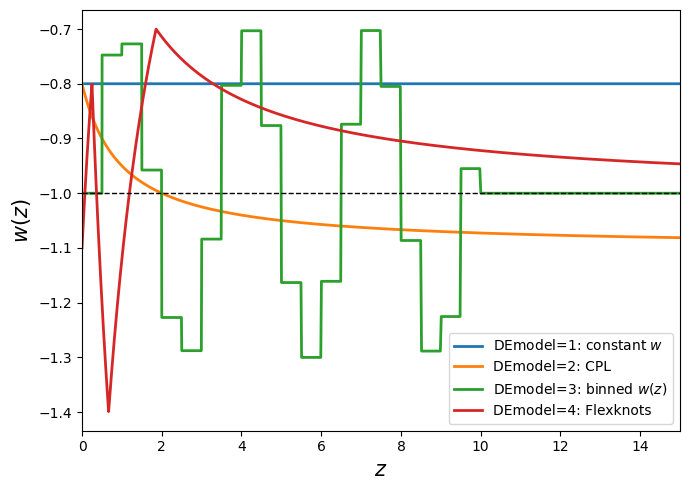

In [27]:
# ------------------------------------------------------------
# Plot w(z)
# ------------------------------------------------------------
plt.figure(figsize=(7, 5))

plt.plot(redshift,wde_w,lw=2,label=r"DEmodel=1: constant $w$")
plt.plot(redshift,wde_cpl,lw=2,label=r"DEmodel=2: CPL")
plt.plot(redshift,wde_bins,lw=2,label=r"DEmodel=3: binned $w(z)$")
plt.plot(redshift,wde_flexknot,lw=2,label=r"DEmodel=4: Flexknots")

plt.axhline(-1, lw=1, ls="--", color="black")

plt.xlim(0, 15)
plt.ylabel(r"$w(z)$", fontsize=15)
plt.xlabel(r"$z$", fontsize=15)
plt.legend(loc="best")
plt.tight_layout()

# plt.savefig("latede_models_w.pdf")
plt.show()

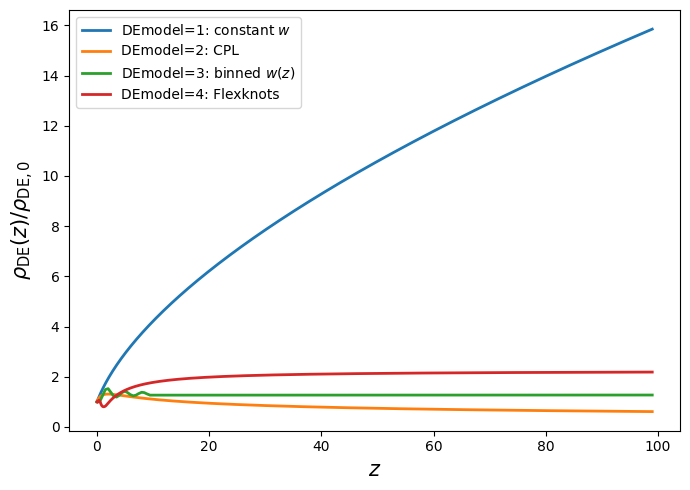

In [28]:
# ------------------------------------------------------------
# Plot rho_DE(a) / rho_DE(a=1)
# ------------------------------------------------------------
plt.figure(figsize=(7, 5))

plt.plot(redshift,rho_w,lw=2,label=r"DEmodel=1: constant $w$")
plt.plot(redshift,rho_cpl,lw=2,label=r"DEmodel=2: CPL")
plt.plot(redshift,rho_bins,lw=2,label=r"DEmodel=3: binned $w(z)$")
plt.plot(redshift,rho_flexnot,lw=2,label=r"DEmodel=4: Flexknots")

plt.ylabel(r"$\rho_{\rm DE}(z)/\rho_{\rm DE,0}$", fontsize=15)
plt.xlabel(r"$z$", fontsize=15)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

# Flexknots

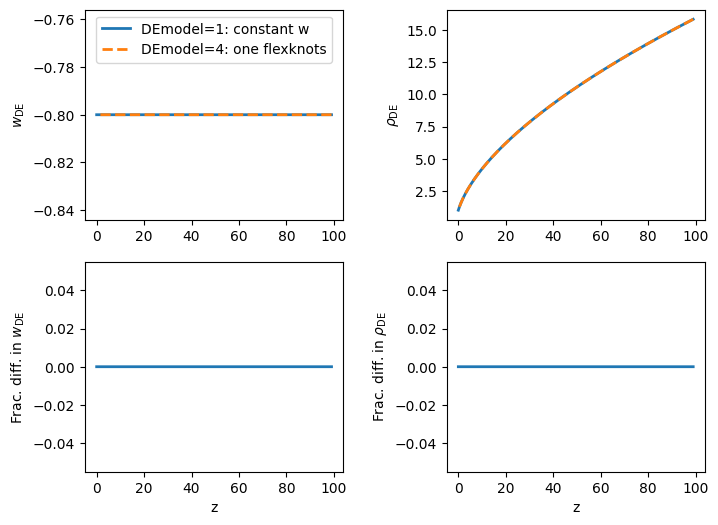

In [29]:
# One knot vs constant w
cosmology_1flexknot = camb.set_params(**base_params,DEmodel=4,a_flexknot=[1.],w_flexknot=[-.8])

# Compute
results_1flexknot = camb.get_results(cosmology_1flexknot)
rho_1flexnot, wde_1flexknot = results_1flexknot.get_dark_energy_rho_w(scale_factor)

fig,ax = plt.subplots(2,2,figsize=(8,6), gridspec_kw={"wspace": 0.4})
ax[0,0].plot(redshift,wde_w,lw=2,label=r"DEmodel=1: constant w")
ax[0,0].plot(redshift,wde_1flexknot,lw=2,ls='--',label=r"DEmodel=4: one flexknots")
ax[0,1].plot(redshift,rho_w,lw=2)
ax[0,1].plot(redshift,rho_1flexnot,lw=2,ls='--')
ax[1,0].plot(redshift,wde_w/wde_1flexknot-1,lw=2)
ax[1,1].plot(redshift,rho_w/rho_1flexnot-1,lw=2)
[ax[1,i].set_xlabel("z") for i in [0,1]]
ax[0,0].set_ylabel(r"$w_{\rm DE}$")
ax[0,1].set_ylabel(r"$\rho_{\rm DE}$")
ax[1,0].set_ylabel(r"Frac. diff. in $w_{\rm DE}$")
ax[1,1].set_ylabel(r"Frac. diff. in $\rho_{\rm DE}$")
ax[0,0].legend(loc='upper center')

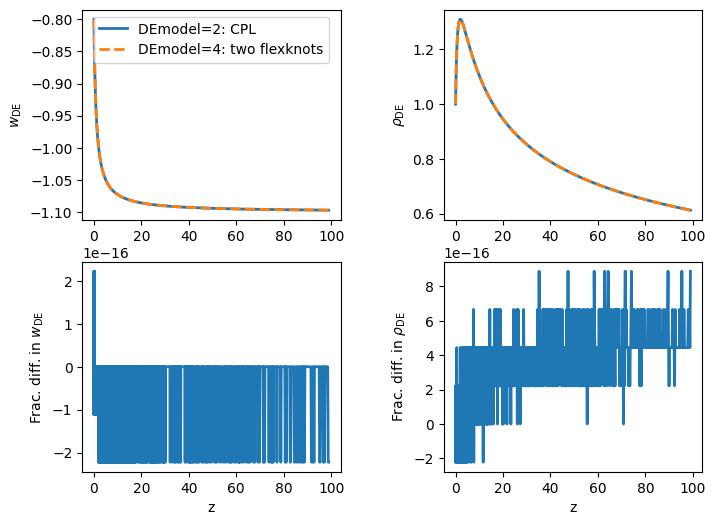

In [30]:
# Two knots vs CPL
w0=-0.8
wa=-0.3

a_flexknot=[0., 1.]
w_flexknot=[w0+wa, w0]

cosmology_2flexknot = camb.set_params(**base_params,DEmodel=4,a_flexknot=a_flexknot,w_flexknot=w_flexknot)

# Compute
results_2flexknot = camb.get_results(cosmology_2flexknot)
rho_2flexnot, wde_2flexknot = results_2flexknot.get_dark_energy_rho_w(scale_factor)

fig,ax = plt.subplots(2,2,figsize=(8,6), gridspec_kw={"wspace": 0.4})
ax[0,0].plot(redshift,wde_cpl,lw=2,label=r"DEmodel=2: CPL")
ax[0,0].plot(redshift,wde_2flexknot,lw=2,ls='--',label=r"DEmodel=4: two flexknots")
ax[0,1].plot(redshift,rho_cpl,lw=2)
ax[0,1].plot(redshift,rho_2flexnot,lw=2,ls='--')
ax[1,0].plot(redshift,wde_cpl/wde_2flexknot-1,lw=2)
ax[1,1].plot(redshift,rho_cpl/rho_2flexnot-1,lw=2)
[ax[1,i].set_xlabel("z") for i in [0,1]]
ax[0,0].set_ylabel(r"$w_{\rm DE}$")
ax[0,1].set_ylabel(r"$\rho_{\rm DE}$")
ax[1,0].set_ylabel(r"Frac. diff. in $w_{\rm DE}$")
ax[1,1].set_ylabel(r"Frac. diff. in $\rho_{\rm DE}$")
ax[0,0].legend(loc='upper center')

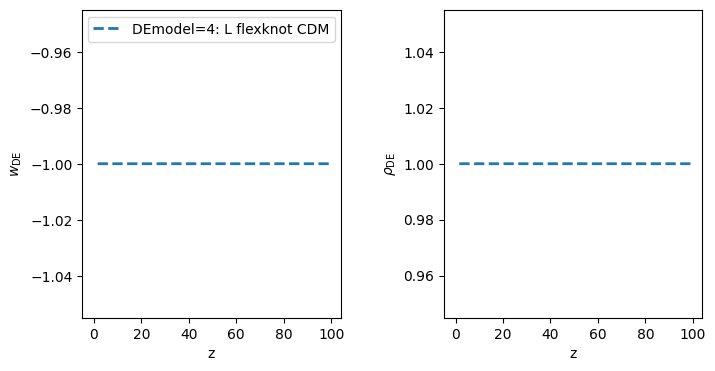

In [31]:
# Pure ΛCDM flexknot
a_flexknot=[0., 0.2, 0.6, 0.9, 1.]
w_flexknot=[-1., -1., -1., -1., -1.]

cosmology_lflexknotcdm = camb.set_params(**base_params,DEmodel=4,a_flexknot=a_flexknot,w_flexknot=w_flexknot)

# Compute
results_lflexknotcdm = camb.get_results(cosmology_lflexknotcdm)
rho_lflexknotcdm, wde_lflexknotcdm = results_lflexknotcdm.get_dark_energy_rho_w(scale_factor)

fig,ax = plt.subplots(1,2,figsize=(8,4), gridspec_kw={"wspace": 0.4})
ax[0].plot(redshift,wde_lflexknotcdm,lw=2,ls='--',label=r"DEmodel=4: L flexknot CDM")
ax[1].plot(redshift,rho_lflexknotcdm,lw=2,ls='--')
[ax[i].set_xlabel("z") for i in [0,1]]
ax[0].set_ylabel(r"$w_{\rm DE}$")
ax[1].set_ylabel(r"$\rho_{\rm DE}$")
ax[0].legend(loc='upper center')

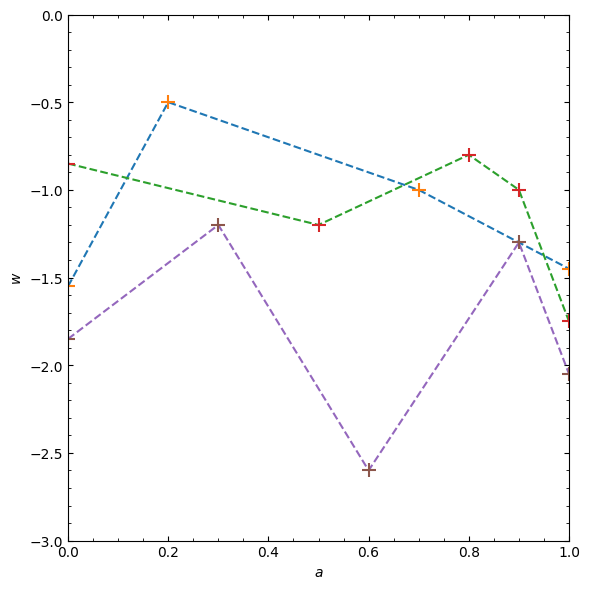

In [32]:
# ------------------------------------------------------------
# Approximate knot coordinates read from Fig. 1 of
# Ormondroyd et al. 2025, arXiv:2503.08658
# ------------------------------------------------------------

examples = [
    (
        [0.0, 0.20, 0.70, 1.0],
        [-1.55, -0.50, -1.00, -1.45],
    ),
    (
        [0.0, 0.50, 0.80, 0.90, 1.0],
        [-0.85, -1.20, -0.80, -1.00, -1.75],
    ),
    (
        [0.0, 0.30, 0.60, 0.90, 1.0],
        [-1.85, -1.20, -2.60, -1.30, -2.05],
    ),
]

agrid = np.linspace(1e-4, 1.0, 1000)
fig, ax = plt.subplots(figsize=(6, 6))

for a_knot, w_knot in examples:
    pars = camb.set_params(**base_params,DEmodel=4,a_flexknot=a_knot,w_flexknot=w_knot)
    results = camb.get_results(pars)
    rho, wde = results.get_dark_energy_rho_w(agrid)
    ax.plot(agrid,wde,'--',lw=1.5)
    ax.plot(a_knot,w_knot,'+',ms=10,mew=1.5)

ax.set_xlim(0, 1)
ax.set_ylim(-3, 0)

ax.set_xlabel(r'$a$')
ax.set_ylabel(r'$w$')

ax.minorticks_on()
ax.tick_params(which='both',direction='in',top=True,right=True)

plt.tight_layout()
plt.show()

# Chebyshev

Check 1: Recover LCDM

Text(0, 0.5, '$\\rho_{\\rm DE}$')

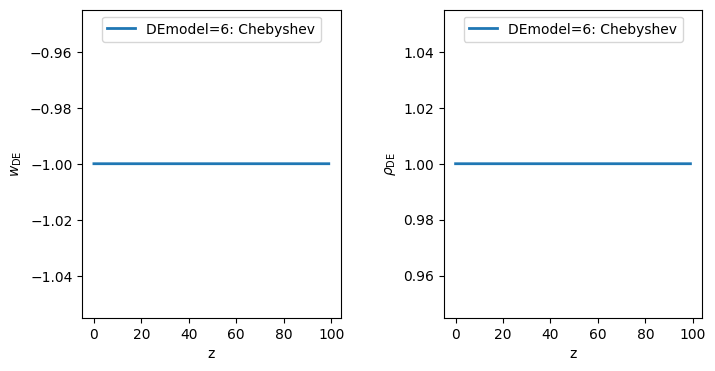

In [33]:
cosmology_cheb_lcdm = camb.set_params(
    **base_params,
    DEmodel=6,
    cheb_c0=1.0,
    cheb_c1=0.0,
    cheb_c2=0.0,
    cheb_c3=0.0,
    cheb_zmax=3.5,
    cheb_delta=1.0,
)

results_cheb_lcdm = camb.get_results(cosmology_cheb_lcdm)
rho_cheb_lcdm, wde_cheb_lcdm = results_cheb_lcdm.get_dark_energy_rho_w(scale_factor)

# ------------------------------------------------------------
# Plot w(z)
# ------------------------------------------------------------
fig,ax = plt.subplots(1,2,figsize=(8,4), gridspec_kw={"wspace": 0.4})

ax[0].plot(redshift,wde_cheb_lcdm,lw=2,label=r"DEmodel=6: Chebyshev")
ax[1].plot(redshift,rho_cheb_lcdm,lw=2,label=r"DEmodel=6: Chebyshev")
[ax[i].legend(loc='upper center') for i in [0,1]]
[ax[i].set_xlabel('z') for i in [0,1]]
ax[0].set_ylabel(r"$w_{\rm DE}$")
ax[1].set_ylabel(r"$\rho_{\rm DE}$")

Check 2: Recover wCDM until zmax

Text(0, 0.5, '$\\rho_{\\rm DE}$')

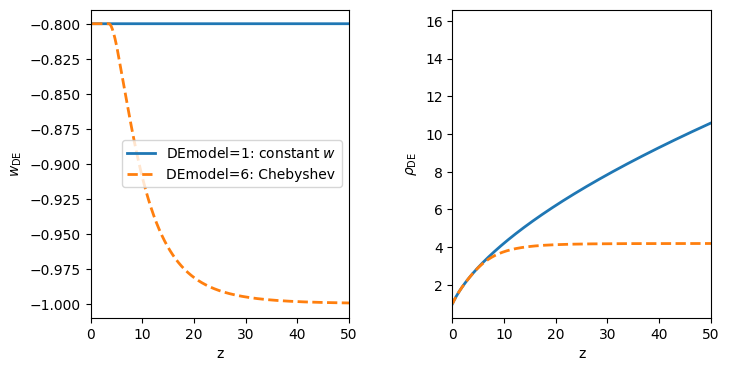

In [34]:
cosmology_cheb_w = camb.set_params(
    **base_params,
    DEmodel=6,
    cheb_c0=0.8,
    cheb_c1=0.0,
    cheb_c2=0.0,
    cheb_c3=0.0,
    cheb_zmax=3.5,
    cheb_delta=1.0,
)

results_cheb_w = camb.get_results(cosmology_cheb_w)
rho_cheb_w, wde_cheb_w = results_cheb_w.get_dark_energy_rho_w(scale_factor)

# ------------------------------------------------------------
# Plot w(z)
# ------------------------------------------------------------
fig,ax = plt.subplots(1,2,figsize=(8,4), gridspec_kw={"wspace": 0.4})

ax[0].plot(redshift,wde_w,lw=2,label=r"DEmodel=1: constant $w$")
ax[1].plot(redshift,rho_w,lw=2)
ax[0].plot(redshift,wde_cheb_w,lw=2,ls='--',label=r"DEmodel=6: Chebyshev")
ax[1].plot(redshift,rho_cheb_w,lw=2,ls='--')
ax[0].set_xlim(0,50)
ax[1].set_xlim(0,50)
ax[0].legend(loc='best')
[ax[i].set_xlabel('z') for i in [0,1]]
ax[0].set_ylabel(r"$w_{\rm DE}$")
ax[1].set_ylabel(r"$\rho_{\rm DE}$")

Check 3: Arbitrary Chebyshev constant values

Text(0, 0.5, '$\\rho_{\\rm DE}$')

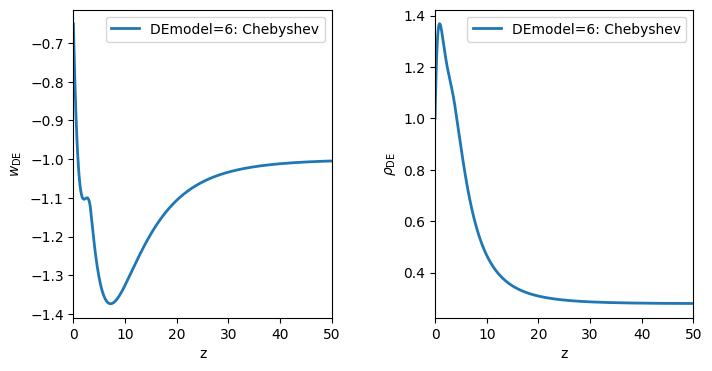

In [35]:
cosmology_cheb = camb.set_params(
    **base_params,
    DEmodel=6,
    cheb_c0=1.0,
    cheb_c1=0.2,
    cheb_c2=-0.1,
    cheb_c3=0.05,
    cheb_zmax=3.5,
    cheb_delta=1.0,
)

results_cheb = camb.get_results(cosmology_cheb)
rho_cheb, wde_cheb = results_cheb.get_dark_energy_rho_w(scale_factor)

# ------------------------------------------------------------
# Plot w(z)
# ------------------------------------------------------------
fig,ax = plt.subplots(1,2,figsize=(8,4), gridspec_kw={"wspace": 0.4})

ax[0].plot(redshift,wde_cheb,lw=2,ls='-',label=r"DEmodel=6: Chebyshev")
ax[1].plot(redshift,rho_cheb,lw=2,ls='-',label=r"DEmodel=6: Chebyshev")
ax[0].set_xlim(0,50)
ax[1].set_xlim(0,50)
ax[0].set_xlim(0,50)
ax[1].set_xlim(0,50)
[ax[i].legend(loc='best') for i in [0,1]]
[ax[i].set_xlabel('z') for i in [0,1]]
ax[0].set_ylabel(r"$w_{\rm DE}$")
ax[1].set_ylabel(r"$\rho_{\rm DE}$")

Check 4  
zoom tightly around the transition  
no discontinuity or kink in the first derivative at z=3.5

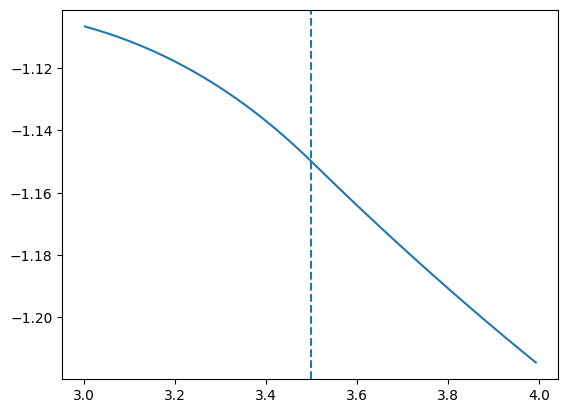

In [36]:
mask = (redshift > 3.0) & (redshift < 4.0)

plt.plot(
    redshift[mask],
    wde_cheb[mask]
)
plt.axvline(3.5, ls="--")

Check 5  
Energy conservation must be satisfied  
$d\ln\rho_{DE}/d\ln(1+z) = 3[1+w(z)]$

In [37]:
lnrho = np.log(rho_cheb)
ln1pz = np.log1p(redshift)

dlnrho_dln1pz = np.gradient(
    lnrho,
    ln1pz
)

rhs = 3.0 * (1.0 + wde_cheb)

mask = (redshift > 0.02) & (redshift < 90)

print(
    "max conservation error =",
    np.max(
        np.abs(
            dlnrho_dln1pz[mask] - rhs[mask]
        )
    )
)

max conservation error = 1.5531681761826732e-05


# Pade-w

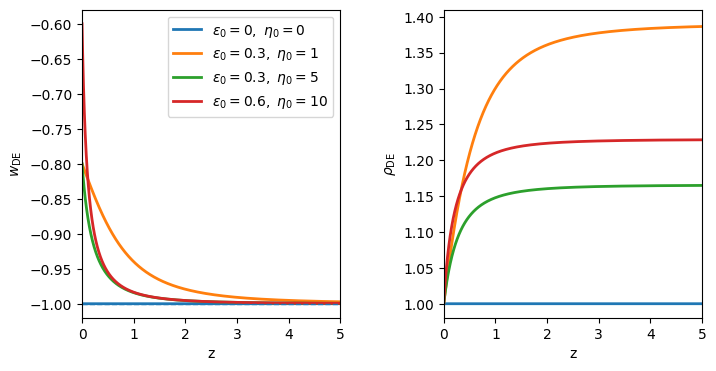

In [38]:
# ------------------------------------------------------------
# DEmodel = 11: Pade-w
# w(a) = -1 + 2 eps0 / (3 + eta0 (a^-3 - 1))
# eps0 = 0 recovers LambdaCDM
# ------------------------------------------------------------
pade_examples = [(0.0, 0.0), (0.3, 1.0), (0.3, 5.0), (0.6, 10.0)]

fig, ax = plt.subplots(1, 2, figsize=(8, 4), gridspec_kw={"wspace": 0.4})

for eps0, eta0 in pade_examples:
    pars = camb.set_params(**base_params, DEmodel=11, pade_eps0=eps0, pade_eta0=eta0)
    results = camb.get_results(pars)
    rho, wde = results.get_dark_energy_rho_w(scale_factor)
    label = r"$\epsilon_0=%g,\ \eta_0=%g$" % (eps0, eta0)
    ax[0].plot(redshift, wde, lw=2, label=label)
    ax[1].plot(redshift, rho, lw=2)

ax[0].axhline(-1, lw=1, ls="--")
[ax[i].set_xlim(0, 5) for i in [0, 1]]
[ax[i].set_xlabel("z") for i in [0, 1]]
ax[0].set_ylabel(r"$w_{\rm DE}$")
ax[1].set_ylabel(r"$\rho_{\rm DE}$")
ax[0].legend(loc="best")
plt.show()

# Thawing scalar field (Shajib & Frieman 2025)

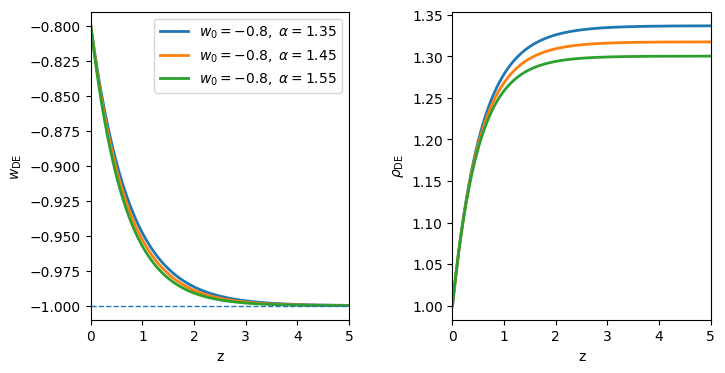

In [39]:
# ------------------------------------------------------------
# DEmodel = 12: thawing scalar-field fit
# Shajib & Frieman 2025, arXiv:2502.06929, Eq. (7)
# w(z) = -1 + (1 + w0) exp(-alpha z)
# The paper uses a flat prior alpha ~ U(1.35, 1.55)
# ------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(8, 4), gridspec_kw={"wspace": 0.4})

for alpha in [1.35, 1.45, 1.55]:
    pars = camb.set_params(**base_params, DEmodel=12, w0=-0.8, thaw_alpha=alpha)
    results = camb.get_results(pars)
    rho, wde = results.get_dark_energy_rho_w(scale_factor)
    ax[0].plot(redshift, wde, lw=2, label=r"$w_0=-0.8,\ \alpha=%g$" % alpha)
    ax[1].plot(redshift, rho, lw=2)

ax[0].axhline(-1, lw=1, ls="--")
[ax[i].set_xlim(0, 5) for i in [0, 1]]
[ax[i].set_xlabel("z") for i in [0, 1]]
ax[0].set_ylabel(r"$w_{\rm DE}$")
ax[1].set_ylabel(r"$\rho_{\rm DE}$")
ax[0].legend(loc="best")
plt.show()

Checks: $\alpha=0$ recovers constant $w=w_0$; energy conservation $d\ln\rho_{DE}/d\ln(1+z) = 3[1+w(z)]$

In [40]:
# Check 1: alpha = 0 recovers constant w = w0
cosmology_thaw_w = camb.set_params(**base_params, DEmodel=12, w0=-0.8, thaw_alpha=0.0)
results_thaw_w = camb.get_results(cosmology_thaw_w)
rho_thaw_w, wde_thaw_w = results_thaw_w.get_dark_energy_rho_w(scale_factor)

print("alpha=0 vs constant w: max frac diff in w   =", np.max(np.abs(wde_thaw_w / wde_w - 1)))
print("alpha=0 vs constant w: max frac diff in rho =", np.max(np.abs(rho_thaw_w / rho_w - 1)))

# Check 2: energy conservation, d ln rho / d ln(1+z) = 3 (1 + w)
cosmology_thaw = camb.set_params(**base_params, DEmodel=12, w0=-0.8, thaw_alpha=1.45)
results_thaw = camb.get_results(cosmology_thaw)
rho_thaw, wde_thaw = results_thaw.get_dark_energy_rho_w(scale_factor)

dlnrho_dln1pz = np.gradient(np.log(rho_thaw), np.log1p(redshift))
mask = (redshift > 0.02) & (redshift < 90)
print("max conservation error =", np.max(np.abs(dlnrho_dln1pz[mask] - 3.0 * (1.0 + wde_thaw[mask]))))

alpha=0 vs constant w: max frac diff in w   = 0.0
alpha=0 vs constant w: max frac diff in rho = 0.0
max conservation error = 6.991278460599659e-07


# Binned $f_{\rm DE}(z)$

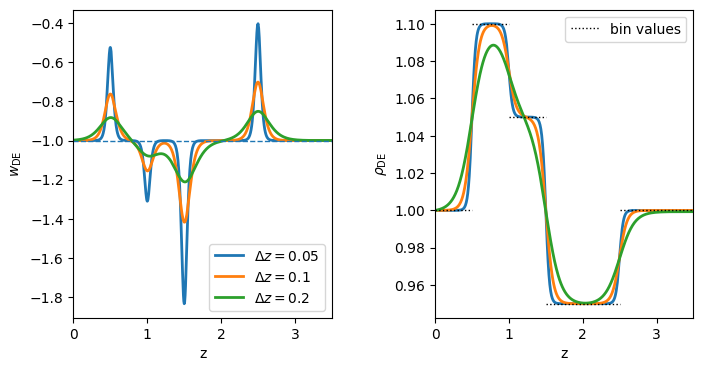

In [41]:
# ------------------------------------------------------------
# DEmodel = 13: binned f_DE(z) = rho_DE(z) / rho_DE(0)
# Piecewise-constant bins smoothed with tanh of width rho_delta (in z):
#   f(z) = r_1 + sum_i (r_i - r_{i-1}) [1 + tanh((z - z_i)/rho_delta)] / 2
# rho_z are the bin lower edges (first = 0), rho_bin the bin values (first = 1).
# Above the last edge rho_DE is constant (w = -1).
# w(z) follows from w = -1 + (1+z)/3 dln(f)/dz
# ------------------------------------------------------------
rho_z = [0.0, 0.5, 1.0, 1.5, 2.5]
rho_bin = [1.0, 1.1, 1.05, 0.95, 1.0]

fig, ax = plt.subplots(1, 2, figsize=(8, 4), gridspec_kw={"wspace": 0.4})

for rho_delta in [0.05, 0.1, 0.2]:
    pars = camb.set_params(**base_params, DEmodel=13, rho_z=rho_z, rho_bin=rho_bin, rho_delta=rho_delta)
    results = camb.get_results(pars)
    rho, wde = results.get_dark_energy_rho_w(scale_factor)
    ax[0].plot(redshift, wde, lw=2, label=r"$\Delta z=%g$" % rho_delta)
    ax[1].plot(redshift, rho, lw=2)

# Bin values, drawn from each lower edge to the next one
edges = rho_z + [3.5]
ax[1].hlines(rho_bin, edges[:-1], edges[1:], colors="k", ls=":", lw=1, label="bin values")

ax[0].axhline(-1, lw=1, ls="--")
[ax[i].set_xlim(0, 3.5) for i in [0, 1]]
[ax[i].set_xlabel("z") for i in [0, 1]]
ax[0].set_ylabel(r"$w_{\rm DE}$")
ax[1].set_ylabel(r"$\rho_{\rm DE}$")
[ax[i].legend(loc="best") for i in [0, 1]]
plt.show()

Checks: all bins equal to 1 recovers ΛCDM; energy conservation $d\ln\rho_{DE}/d\ln(1+z) = 3[1+w(z)]$

In [42]:
# Check 1: all bin values = 1 recovers LambdaCDM (w = -1, constant rho)
cosmology_fde_lcdm = camb.set_params(**base_params, DEmodel=13, rho_z=rho_z, rho_bin=np.ones(len(rho_z)), rho_delta=0.1)
results_fde_lcdm = camb.get_results(cosmology_fde_lcdm)
rho_fde_lcdm, wde_fde_lcdm = results_fde_lcdm.get_dark_energy_rho_w(scale_factor)
print("all bins = 1: max |w + 1|            =", np.max(np.abs(wde_fde_lcdm + 1)))
print("all bins = 1: max |rho/rho_today - 1| =", np.max(np.abs(rho_fde_lcdm - 1)))

# Check 2: energy conservation, d ln rho / d ln(1+z) = 3 (1 + w)
cosmology_fde = camb.set_params(**base_params, DEmodel=13, rho_z=rho_z, rho_bin=rho_bin, rho_delta=0.2)
results_fde = camb.get_results(cosmology_fde)
rho_fde, wde_fde = results_fde.get_dark_energy_rho_w(scale_factor)

dlnrho_dln1pz = np.gradient(np.log(rho_fde), np.log1p(redshift))
mask = (redshift > 0.02) & (redshift < 90)
print("max conservation error =", np.max(np.abs(dlnrho_dln1pz[mask] - 3.0 * (1.0 + wde_fde[mask]))))

all bins = 1: max |w + 1|            = 0.0
all bins = 1: max |rho/rho_today - 1| = 0.0
max conservation error = 0.00024361615281653926
